# Prétraitement ERA5-Land Algérie (2015-2026)

Le notebook suit l'ordre du cours : Chapitre 4 (nettoyage et prétraitement), puis encodage du Chapitre 5. Chaque titre indique la partie du cours correspondante.

## 0. Configuration

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/data mining"
except ImportError:
    BASE = "."
DATA_PATH = f"{BASE}/era5_land_algeria_2x2_tidy.parquet"
SORTIE = f"{BASE}/data_preprocessed"
os.makedirs(SORTIE, exist_ok=True)

VARS = ["t2m", "d2m", "slhf", "ssr", "str", "sshf", "ro", "e", "u10", "v10", "sp", "tp"]
FLUX = ["ssr", "str", "sshf"]      # variables touchées par l'erreur de la source

Mounted at /content/drive


## 1.  Data Quality
On vérifie la complétude (valeurs manquantes), l'exactitude et la cohérence (doublons, panel complet, période).

In [2]:
df = pd.read_parquet(DATA_PATH).sort_values(["cell_id", "time"]).reset_index(drop=True)

print("Dimensions :", df.shape)
print("NaN :", int(df[VARS].isna().sum().sum()), "| doublons :", int(df.duplicated(["cell_id", "time"]).sum()))
print("Panel complet :", df["cell_id"].nunique() * df["time"].nunique() == len(df))
print("Période :", df["time"].min().date(), "->", df["time"].max().date())

desc = df[VARS].describe().T[["mean", "50%", "std", "min", "max"]]
desc["asymétrie"] = df[VARS].skew()
desc.round(3)

Dimensions : (764925, 18)
NaN : 0 | doublons : 0
Panel complet : True
Période : 2015-01-01 -> 2026-09-01


,mean,50%,std,min,max,asymétrie
t2m,2.389500e+01,2.422600e+01,8.749,2.750000e-01,4.103000e+01,-0.126000
d2m,1.540000e+00,1.321000e+00,4.828,-1.695100e+01,2.258100e+01,0.284000
slhf,-4.977903e+05,-1.821055e+05,982610.312,-1.104461e+07,-3.608250e+03,-4.074000
ssr,1.351044e+07,1.397466e+07,4241319.000,2.787183e+06,2.531261e+07,-0.208000
str,-9.512686e+06,-9.921888e+06,2604342.500,-1.499557e+07,-2.138827e+06,0.584000
sshf,-3.394623e+06,-3.415796e+06,1931648.875,-1.438424e+07,5.862678e+06,-0.452000
ro,3.000000e-03,0.000000e+00,0.033,0.000000e+00,4.795000e+00,36.689999
e,-1.990000e-01,-7.300000e-02,0.393,-4.416000e+00,-1.000000e-03,-4.074000
u10,-1.025000e+00,-9.950000e-01,1.589,-6.719000e+00,7.477000e+00,0.081000
v10,-5.140000e-01,-4.660000e-01,1.045,-4.673000e+00,3.313000e+00,-0.239000


## 2. Valeurs manquantes
Le fichier n'a aucun NaN, mais de septembre 2022 à février 2024, ssr, str et sshf sont à environ la moitié de leur valeur normale (erreur connue de la source). Ces valeurs sont fausses : on les repère, on les met à NaN, puis on les remplace.

on a :
 - l'imputation classique (moyenne globale),
 - l'imputation intelligente par groupe
 - les modèles prédictifs (kNN, régression).

 Ici on utilise l'imputation par groupe : la moyenne de la même cellule pour le même mois, calculée sur les mois normaux. On la compare à la moyenne globale sur l'année 2019 que l'on masque.

In [3]:
# 1) détection : valeur du mois / valeur normale du mois (calculée hors 2022-2024)
moy = df.groupby("time")[FLUX].mean()
ref = moy[~moy.index.year.isin([2022, 2023, 2024])]
ratio = moy / ref.groupby(ref.index.month).mean().loc[moy.index.month].values
mois_suspects = ratio.index[(ratio < 0.75).all(axis=1)]
print("Mois suspects :", mois_suspects.min().date(), "->", mois_suspects.max().date(), f"({len(mois_suspects)} mois)")

# 2) mise à NaN
df_nan = df.copy()
df_nan.loc[df_nan["time"].isin(mois_suspects), FLUX] = np.nan
print(f"Valeurs mises à NaN : {df_nan[FLUX].isna().any(axis=1).mean()*100:.1f} % des lignes")

Mois suspects : 2022-09-01 -> 2024-02-01 (18 mois)
Valeurs mises à NaN : 12.8 % des lignes


                              ssr        str       sshf
moyenne globale         3633138.0  1921233.0  1862845.0
moyenne cellule x mois   375313.0   422622.0   358606.0
NaN restants : 0


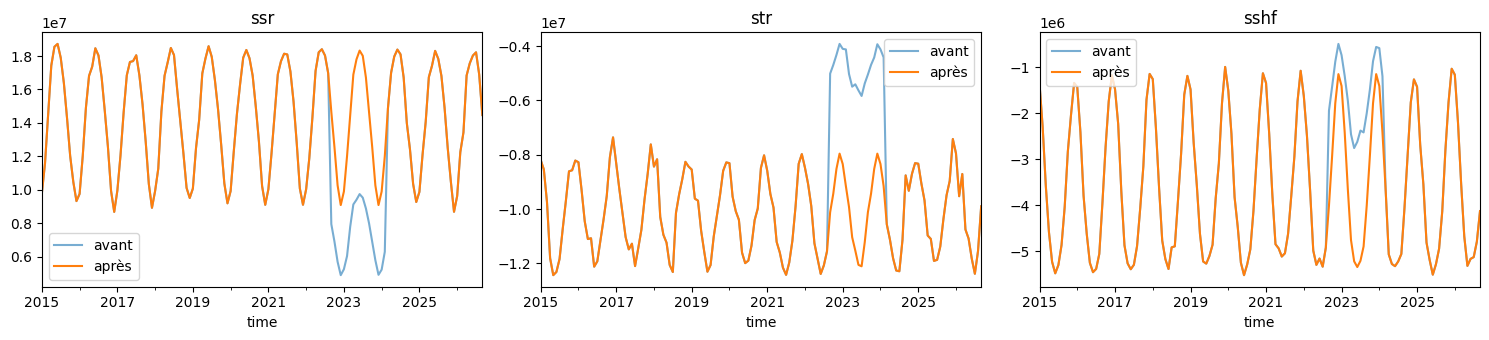

In [4]:
# 3) comparaison des deux imputations sur 2019 masquée (erreur RMSE, plus petit = meilleur)
normal = df_nan.dropna(subset=FLUX)
verif, appr = normal[normal["year"] == 2019], normal[normal["year"] != 2019]
idx = pd.MultiIndex.from_arrays([verif["cell_id"], verif["month"]])
rmse = {}
for c in FLUX:
    p_cm = appr.groupby(["cell_id", "month"])[c].mean().reindex(idx).values
    rmse[c] = {"moyenne globale": np.sqrt(np.mean((verif[c] - appr[c].mean()) ** 2)),
               "moyenne cellule x mois": np.sqrt(np.mean((verif[c].values - p_cm) ** 2))}
print(pd.DataFrame(rmse).round(0))

# 4) imputation par groupe (cellule x mois)
df_clean = df_nan.copy()
for c in FLUX:
    df_clean[c] = df_clean[c].fillna(df_clean.groupby(["cell_id", "month"])[c].transform("mean"))
print("NaN restants :", int(df_clean[VARS].isna().sum().sum()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, FLUX):
    df.groupby("time")[c].mean().plot(ax=ax, label="avant", alpha=0.6)
    df_clean.groupby("time")[c].mean().plot(ax=ax, label="après")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

## 3. Outliers (Log x)
Détection avec:
-  le Z-score (|Z| > 3)
- la règle IQR
- histogrammes et boxplots.

Les variables tp, ro, e (et slhf) sont signalées pour 15 à 16 % des lignes par l'IQR. Ce sont de vraies pluies et de vrais flux, la distribution est simplement très asymétrique : on ne supprime aucune ligne.

Traitement choisi : transformation mathématique (log). On utilise un log signé, signe(x) * log(1 + |x|), car e est négative. Pour tp et ro (positives) c'est log1p. Les colonnes d'origine sont conservées.

variable  % outliers IQR  % outliers Z-score
     t2m            0.00                0.00
     d2m            1.12                0.51
    slhf           16.43                2.84
     ssr            0.00                0.00
     str            0.07                0.05
    sshf            0.93                0.66
      ro           16.20                0.72
       e           16.43                2.84
     u10            0.73                0.41
     v10            1.07                0.22
      sp            1.82                0.49
      tp           15.11                2.40


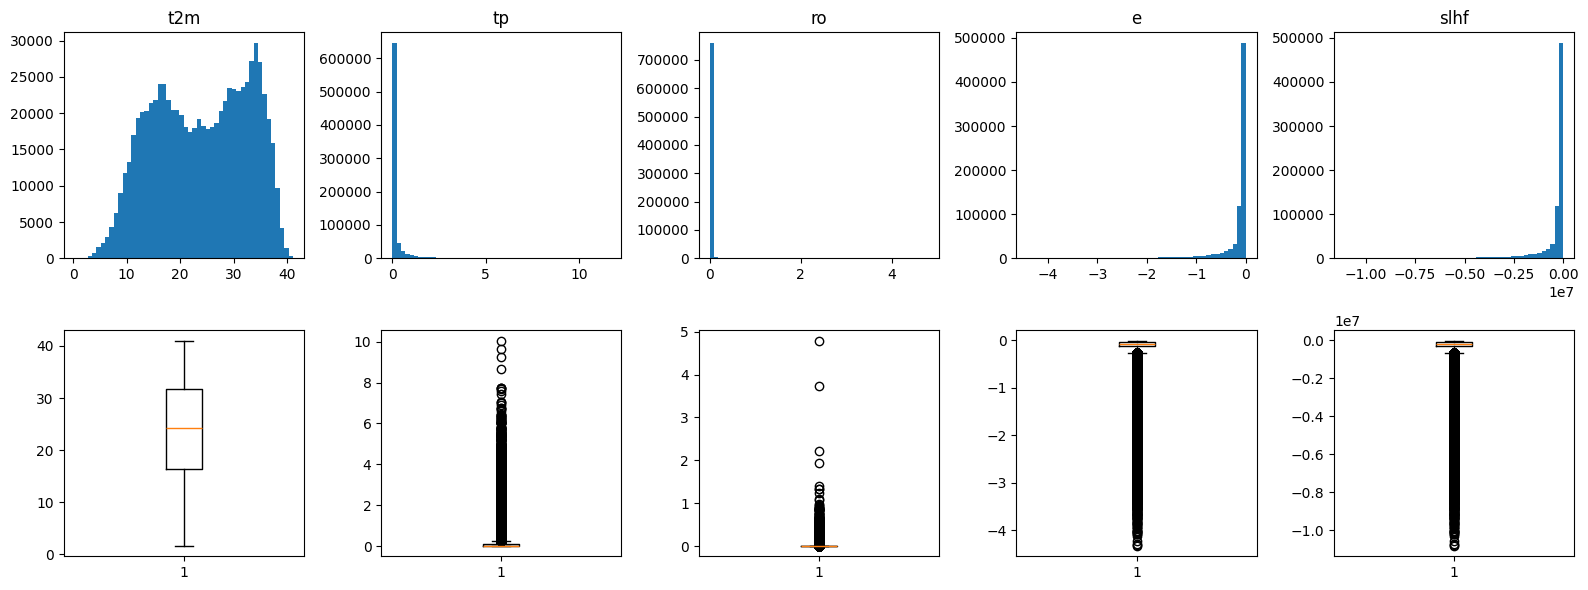

In [5]:
lignes = []
for v in VARS:
    x = df_clean[v]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    n_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100
    n_z = (((x - x.mean()) / x.std()).abs() > 3).mean() * 100
    lignes.append([v, round(n_iqr, 2), round(n_z, 2)])
print(pd.DataFrame(lignes, columns=["variable", "% outliers IQR", "% outliers Z-score"]).to_string(index=False))

montrer = ["t2m", "tp", "ro", "e", "slhf"]       # t2m sert de référence symétrique
ech = df_clean.sample(min(100_000, len(df_clean)), random_state=0)
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for j, v in enumerate(montrer):
    axes[0, j].hist(df_clean[v], bins=50); axes[0, j].set_title(v)
    axes[1, j].boxplot(ech[v], vert=True)
plt.tight_layout(); plt.show()

In [6]:
def log_signe(x):
    return np.sign(x) * np.log1p(np.abs(x))

A_LOG = ["tp", "ro", "e"]
for c in A_LOG:
    df_clean[c + "_log"] = log_signe(df_clean[c])

print(pd.DataFrame({"asymétrie avant": df_clean[A_LOG].skew(),
                    "asymétrie après": df_clean[[c + "_log" for c in A_LOG]].skew().set_axis(A_LOG)}).round(2))

    asymétrie avant  asymétrie après
tp         5.730000             3.35
ro        36.689999            19.82
e         -4.070000            -2.90


## 4. Dimensiality Reduction
eliminer:
-  les variables à faible variance (< 0,01)
- les variables fortement corrélées (> 90 %) car doublons / redandonce
- les variables avec trop de nuls (> 50 %)

Pour la corrélation on utilise Spearman, adaptée aux distributions asymétriques.

Pour la variance, la valeur brute dépend de l'unité, donc on regarde aussi le coefficient de variation (écart-type / |moyenne|), non interprétable pour t2m et d2m (°C).

In [7]:
tab = pd.DataFrame({"variance": df_clean[VARS].var(),
                    "CV": df_clean[VARS].std() / df_clean[VARS].mean().abs(),
                    "% zéros": (df_clean[VARS] == 0).mean() * 100})
tab.loc[["t2m", "d2m"], "CV"] = np.nan
print(tab.to_string(float_format=lambda x: f"{x:.3g}"))

spearman = df_clean[VARS].sample(min(200_000, len(df_clean)), random_state=42).corr(method="spearman")
print("\nPaires avec |corrélation| > 0.9 :")
for i, a in enumerate(VARS):
    for b in VARS[i + 1:]:
        if abs(spearman.loc[a, b]) > 0.9:
            print(f"  {a} - {b} : {spearman.loc[a, b]:.2f}")

      variance     CV  % zéros
t2m       76.5    NaN        0
d2m       23.3    NaN        0
slhf  9.66e+11   1.97        0
ssr   1.33e+13  0.255        0
str   3.84e+12  0.193        0
sshf  3.56e+12  0.524        0
ro     0.00106   9.57     19.4
e        0.154   1.97        0
u10       2.52   1.55        0
v10       1.09   2.03        0
sp    1.12e+03 0.0352        0
tp       0.223   2.75        0

Paires avec |corrélation| > 0.9 :
  slhf - e : 1.00
  ssr - sshf : -0.96
  ro - tp : 0.98


Décisions :
- Faible variance : seule ro a une variance brute inférieure à 0,01, mais c'est à cause de son unité (mm/jour). Son coefficient de variation est élevé : on la garde.
- Nuls : ro a environ 19 % de zéros (zones arides, vrais zéros), sous le seuil de 50 % : on la garde.
- Corrélation : slhf et e sont identiques (1,00), on supprime slhf. ssr, str et sshf sont aussi très corrélées, mais le sujet impose de les garder.


In [8]:
df_clean = df_clean.drop(columns=["slhf"])
VARS = [v for v in VARS if v != "slhf"]
print("Variables restantes :", VARS)

Variables restantes : ['t2m', 'd2m', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


## 5. Numerosity Reduction
Aucun doublon (section 1). Pas d'échantillonnage : environ 765 000 lignes, un volume raisonnable, et on veut garder tous les mois et toutes les cellules. Pas d'agrégation supplémentaire : la grille est à 0,2 degré, ce qui correspond déjà à un regroupement 2x2 des mailles ERA5-Land à 0,1 degré.

## 6. Feature Encoding
Encodage cyclique du mois : sinus et cosinus, pour que décembre (12) soit proche de janvier (1).

In [9]:
df_clean = df_clean.sort_values(["cell_id", "time"]).reset_index(drop=True)
df_clean["month_sin"] = np.sin(2 * np.pi * df_clean["month"] / 12)
df_clean["month_cos"] = np.cos(2 * np.pi * df_clean["month"] / 12)
df_clean[["month", "month_sin", "month_cos"]].drop_duplicates().sort_values("month").round(2).reset_index(drop=True)

,month,month_sin,month_cos
0,1,0.50,0.87
1,2,0.87,0.50
2,3,1.00,0.00
3,4,0.87,-0.50
4,5,0.50,-0.87
5,6,0.00,-1.00
6,7,-0.50,-0.87
7,8,-0.87,-0.50
8,9,-1.00,-0.00
9,10,-0.87,0.50


## 7. Sauvegarde
On sauvegarde le jeu de données nettoyé (mois corrigés, `slhf` supprimée, colonnes log et encodage cyclique du mois) ainsi que les décisions prises.

In [10]:
df_clean.to_parquet(f"{SORTIE}/df_clean.parquet")
json.dump({"mois_corriges": [str(m.date()) for m in mois_suspects], "colonne_supprimee": "slhf",
           "colonnes_log": A_LOG}, open(f"{SORTIE}/params.json", "w"), indent=2)
print("Jeu nettoyé :", df_clean.shape, "| fichiers dans", SORTIE)

Jeu nettoyé : (764925, 22) | fichiers dans /content/drive/MyDrive/data mining/data_preprocessed


## 8. Pour aller plus loin (non appliqué)
- Imputation par modèle prédictif (kNN, régression) : le cours les recommande quand plus de 5 % des valeurs manquent. Ici 3 variables sur 11 sont concernées et l'imputation par groupe a été validée sur 2019, mais un modèle pourrait estimer ssr, str et sshf à partir des autres variables. On peut aussi retélécharger les mois corrigés depuis ERA5-Land.
- Réduction par projection (PCA, t-SNE, UMAP) : regrouper ssr, str et sshf, très corrélées, en composantes principales. Utile surtout pour le clustering et la visualisation.
- Modèles robustes aux valeurs extrêmes (Random Forest) à la place de la transformation log.